# Adaptive $\gamma$ and likelihood annealing: a $2\times2$ decomposition

CI-EnSF carries two online adaptations. This notebook switches each on and off independently
and reports the four combinations.

| | $\mathbf{R}$ fixed | $\mathbf{R}$ annealed |
|---|---|---|
| $\gamma$ fixed | neither | annealing only |
| $\gamma$ adaptive | controller only | both |

*Adaptive $\gamma$* sets the width of the prior the transport starts from, updated from the
innovation-consistency ratio by
$\gamma \leftarrow \mathrm{clip}(\gamma\,\rho_s^{1/2}, 0.05, 0.15)$. Switching it off holds
$\gamma$ at $\gamma_0 = 0.1$ for the whole run.

*Likelihood annealing* replaces $\mathbf{R}$ by
$\mathbf{R}_{\rm eff} = \max(\mathbf{R}, \kappa\,\overline{d^2})$, which returns to
$\mathbf{R}$ by itself as the innovations shrink. Switching it off means $\kappa = 0$.

**Scenario.** Identical to the arctan cold-start experiment: Lorenz-96, $d = 40$,
$N_e = 20$, $h(x) = \arctan(x)$, $\sigma_{\rm obs} = 0.05$, $50\,\%$ coverage,
$\Delta t_{\rm obs} = 0.2$, a climatological initial ensemble, 80 cycles with cycles 40-79
scored, 40 evaluation seeds. Only CI-EnSF is run. The hyperparameters are the ones selected
there — $\gamma_0 = 0.1$, $L = 1.5$, $N_t = 400$, $\kappa = 0.025$,
$\gamma \in [0.05, 0.15]$ — and are not re-tuned per cell.

The *adaptive + on* cell is by construction the CI-EnSF configuration of Table 2: $40/40$
seeds, RMSE $0.3959$, spread/RMSE $1.02$. The notebook asserts that it reproduces them.

**Produces** Table 3 and Figure 4 of the manuscript. Set `RUN_SIMULATION = False` to rebuild
them from `adapt2x2_cache.npz`.

## 1. Configuration

In [1]:
import numpy as np, time, json
import matplotlib
import matplotlib.pyplot as plt

# ---------------- model
D            = 40          # state dimension
F_FORCING    = 8.0         # Lorenz-96 forcing
DT_TRUTH     = 0.01        # integration step for the truth
DT_MODEL     = 0.02        # integration step for the forecast model (deliberately coarser)
DT_OBS       = 0.2         # analysis interval.  L96 at F=8 has a doubling time of 0.42,
                           # so this is half a doubling time -- the standard setting.
SPINUP_STEPS = 2000        # steps to reach the attractor before the truth run starts

# ---------------- observations
OBS_STRIDE   = 2           # observe every 2nd variable -> 50 % coverage
SIGMA_OBS    = 0.05        # observation error standard deviation, IN OBSERVATION
                           # SPACE.  The equivalent state-space error is
                           # sigma_obs/h'(x) = sigma_obs (1 + x^2); see the header.

# ---------------- ensemble
K            = 20          # ensemble members
COLD_START   = True        # the initial ensemble is drawn from the model CLIMATOLOGY, not
                           # from a perturbation of the truth: the filter begins a full
                           # climatological standard deviation away and has to find the
                           # truth on its own.  This is the difficulty this experiment adds.
CLIM_POOL_N  = 400         # states in the climatological pool
CLIM_GAP     = 100         # DT_TRUTH steps between pool states (1.0 time units, about two
                           # error-doubling times, so the members are effectively independent
                           # draws from the attractor)
CLIM_SEED    = 987654321   # the pool is a property of the MODEL, not of a seed

# ---------------- experiment
N_CYCLES     = 80          # 80, not 40: the climatological transient has to clear before
                           # any steady-state score means anything
SCORE_SKIP   = 0.5         # score cycles 40-79.  The transient clears by cycle ~30 for all
                           # three methods (measured out to 150 cycles), so this leaves a
                           # 10-cycle margin.  Fixed before any evaluation seed was run.
TUNE_SEEDS   = tuple(range(100, 120))   # 20, not 5, and disjoint from the evaluation seeds.
                           # What this experiment turns on is the FAILURE RATE, and five
                           # seeds cannot resolve it: with five, every top CI-EnSF setting
                           # survived 5/5, selection fell back to RMSE alone and chose the
                           # configuration with no adaptive control, which then failed 27 of
                           # the 40 evaluation seeds.  With twenty the same search chose the
                           # controlled configuration and 30 of 40 survived.
EVAL_SEEDS   = tuple(range(40))   # 40, not 10: what this experiment turns on is the
                                  # FAILURE RATE, which ten seeds cannot resolve
EPS_C        = 1e-6        # ridge added to B before its eigendecomposition
STD_FLOOR    = 1e-8

obs_idx  = np.arange(0, D, OBS_STRIDE)
obs_mask = np.zeros(D, bool); obs_mask[obs_idx] = True
Q        = obs_idx.size
R_DIAG   = np.full(Q, SIGMA_OBS**2)

# ---------------- the 2x2
GAMMA0   = 0.1             # the selected value; also the fixed value when ctrl = "off"
L_LOC    = 1.5
N_STEPS  = 400             # NOT the 1600 of the previous experiment's first draft.  At 1600
                           # the step count alone removes every failure, annealing has nothing
                           # left to contribute and the 2x2 has no stability signal to
                           # decompose.  400 is where the two adaptations actually compete,
                           # and it is the step count the arctan experiment now uses, so cell
                           # (d) here is exactly the configuration reported there.
KAPPA    = 0.025           # annealing strength, the value the arctan experiment uses.
# The simplified controller has a single adaptive form, so the first axis of the 2x2 is
# just fixed vs adaptive gamma; the one-sided / two-sided distinction the old rule needed
# no longer exists.
CELLS = {"(a) neither":          dict(ctrl="off", kappa=0.0),
         "(b) controller only":  dict(ctrl="on",  kappa=0.0),
         "(c) annealing only":   dict(ctrl="off", kappa=KAPPA),
         "(d) both":             dict(ctrl="on",  kappa=KAPPA)}

### Recomputation switch

`RUN_SIMULATION = False` rebuilds the table and the figure from `adapt2x2_cache.npz`.

In [2]:
import os, json
RUN_SIMULATION = False         # False -> load exp1_cache.npz and only redraw
CACHE = "adapt2x2_cache.npz"

def save_cache(**kw):
    # compressed: the JSON payloads are stored by numpy as UTF-32, four bytes per
    # character, so an uncompressed cache is several times larger than it needs to be.
    np.savez_compressed(CACHE, **{k: (v if isinstance(v, np.ndarray) else np.array(json.dumps(v)))
                                  for k, v in kw.items()})

def load_cache():
    z = np.load(CACHE, allow_pickle=False)
    return {k: (json.loads(str(z[k])) if z[k].dtype.kind in "US" else z[k]) for k in z.files}

if not RUN_SIMULATION and not os.path.exists(CACHE):
    raise SystemExit("RUN_SIMULATION = False but %s is missing; run once with True." % CACHE)


## 2. Model, observation operator and the climatological ensemble

In [3]:
def l96_rhs(x):
    return (np.roll(x, -1, -1) - np.roll(x, 2, -1))*np.roll(x, 1, -1) - x + F_FORCING

def rk4(x, dt, steps):
    for _ in range(steps):
        k1 = l96_rhs(x); k2 = l96_rhs(x + 0.5*dt*k1)
        k3 = l96_rhs(x + 0.5*dt*k2); k4 = l96_rhs(x + dt*k3)
        x = x + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)
    return x

# ---------------- the climatological initial ensemble
_POOL = None
def clim_pool():
    """A long free run of the model, sampled at intervals long enough to decorrelate."""
    global _POOL
    if _POOL is None:
        r = np.random.default_rng(CLIM_SEED)
        x = rk4(r.normal(scale=3.0, size=D), DT_TRUTH, SPINUP_STEPS)
        P = np.empty((CLIM_POOL_N, D))
        for i in range(CLIM_POOL_N):
            P[i] = x; x = rk4(x, DT_TRUTH, CLIM_GAP)
        _POOL = P
    return _POOL

def climatological_ensemble(rng):
    """K members drawn without replacement from the pool.  Not re-centred on anything: the
    mean is the climatological mean and the spread is the climatological spread."""
    P = clim_pool()
    return P[rng.choice(len(P), size=K, replace=False)].copy()

M_op     = lambda v: np.arctan(v)          # saturating observation operator
M_prime  = lambda v: 1.0/(1.0 + v**2)      # h'(x) -> 0 as |x| grows

def make_truth(seed, n_cycles):
    """Truth trajectory and initial ensemble.  The rng is returned and reused so that the
    observation noise and every filter's own draws come from ONE stream per seed."""
    rng = np.random.default_rng(seed)
    x = rk4(rng.normal(scale=3.0, size=D), DT_TRUTH, SPINUP_STEPS)
    T = np.empty((n_cycles, D))
    for n in range(n_cycles):
        T[n] = x
        x = rk4(x, DT_TRUTH, int(round(DT_OBS/DT_TRUTH)))
    X0 = climatological_ensemble(rng)
    return T, X0, rng

_T, _, _ = make_truth(0, 400)
CLIM_STD = float(_T.std())
FAIL_RMSE = 0.5*CLIM_STD        # filter-divergence threshold

## 3. Localization and $\mathbf{C}$

$\mathbf{C}$ is the localized correlation matrix of the standardized ensemble, Eq. (17),
with $\mathbf{C}_{\rm loc}$ the indicator of the Gaspari-Cohn support and
$\varepsilon = 10^{-6}$. Its eigenvalues are clipped at zero, which an indicator taper
requires. In the code it is `Cm`.


In [4]:
def rho_gc(rr):
    """Gaspari-Cohn, compactly supported on rr < 2."""
    rr = np.abs(np.asarray(rr, float)); out = np.zeros_like(rr)
    n = rr <= 1; x = rr[n]; out[n] = 1 - (5/3)*x**2 + (5/8)*x**3 + 0.5*x**4 - 0.25*x**5
    f = (rr > 1) & (rr < 2); x = rr[f]
    out[f] = 4 - 5*x + (5/3)*x**2 + (5/8)*x**3 - 0.5*x**4 + x**5/12 - 2/(3*x)
    return out

DIST = np.minimum(np.abs(np.arange(D)[:,None] - np.arange(D)[None,:]),
                  D - np.abs(np.arange(D)[:,None] - np.arange(D)[None,:]))

_TAPER = {}
def taper_matrix(L_loc):
    """Indicator taper at scale L_loc (support ends at 2*L_loc)."""
    key = float(L_loc)
    if key not in _TAPER:
        _TAPER[key] = (rho_gc(DIST/float(L_loc)) > 0).astype(float)
    return _TAPER[key]

def build_C(U, L_loc):
    """Localized correlation of the standardized ensemble U (K, d), and a square root.

    The eigenvalue clip is not optional: running the transport with the raw, unclipped
    Schur product loses every seed within a few cycles, because the indicator taper is not
    positive semidefinite (its smallest eigenvalue is about -2.4 at L_loc = 3)."""
    A  = U - U.mean(0)
    P  = taper_matrix(L_loc)*((A.T @ A)/(K - 1))
    Cm = (P + EPS_C*np.eye(D))/(1.0 + EPS_C)
    lam, QB = np.linalg.eigh(0.5*(Cm + Cm.T))
    lam = np.maximum(lam, 0.0)
    return (QB*lam) @ QB.T, QB*np.sqrt(lam)

def standardize(Xf):
    shift = Xf.mean(0)
    std   = np.maximum(Xf.std(0, ddof=1), STD_FLOOR)
    return shift, std, (Xf - shift)/std


## 4. The two adaptations

$\rho$ is the innovation-consistency ratio of Eq. (49), smoothed by an exponential moving
average with weight $w_{\rm EMA} = 0.3$. It is formed with the true $\mathbf{R}$, never with
$\mathbf{R}_{\rm eff}$.

In [5]:
W_SMOOTH, P_GAIN = 0.3, 0.5
GAMMA_LO, GAMMA_HI = 0.05, 0.15

def innovation_ratio(Xf, y):
    """rho = sum d^2 / sum[(1 + 1/K) s_f^2 + r].  Target 1.  The (1 + 1/K) is the
    finite-ensemble correction; without it rho is biased high by 5 % at K = 20.

    R_DIAG here is the TRUE observation error, deliberately, even when the analysis is
    running with an annealed r_eff: this has to report whether the ensemble is genuinely
    consistent, and passing r_eff would drive rho to 1 by construction."""
    hx = M_op(Xf[:, obs_idx]); d = y - hx.mean(0)
    return float(d @ d / np.sum((1.0 + 1.0/K)*hx.var(0, ddof=1) + R_DIAG))

def update_gamma(gamma, rho_s, ctrl="on"):
    """on  : one multiplicative feedback, clipped.  Its fixed point is exactly rho_s = 1,
             which is the statistically meaningful condition, and it has two constants
             rather than four.  P_GAIN = 1/2 because rho is a variance ratio and gamma a
             variance.  This is Eq. (51) of the manuscript.
       off : no control -- gamma stays at GAMMA0 for the whole run.

    The dead band and geometric decay this replaced had no interior fixed point: above the
    band gamma climbed, below it decayed at a fixed rate however far below rho_s was, so it
    only ever rested on a bound.  The two were compared over 40 seeds in
    gamma_controller.ipynb and were statistically indistinguishable."""
    if ctrl == "off": return gamma
    return float(min(max(gamma*rho_s**P_GAIN, GAMMA_LO), GAMMA_HI))

def anneal_R(d_innov, kappa):
    """r_eff = max(R, kappa * mean(d^2)).

    E[d d'] = H P^f H' + R, so this turns the likelihood transport's R^-1 into
    (H P^f H' + R)^-1 -- the LETKF's denominator -- whenever the background is much more
    uncertain than the observations.  Self-annealing: the innovations shrink as the filter
    converges and the max() returns to R with no external schedule.

    The SAME r_eff must be used for the perturbed observations inside the analysis, or the
    randomization is inconsistent with the likelihood and the analysis under-disperses."""
    if kappa <= 0: return R_DIAG
    return np.maximum(R_DIAG, kappa*float(np.mean(d_innov**2)))

## 5. CI-EnSF

The same implementation as the arctan experiment, with $r_{\rm eff}$ passed in so that the
perturbed observations and the likelihood use the same value.

In [6]:
def cvt_ensf(Xf, y, rng, gamma=0.1, L_loc=1.5, n_steps=1600, t_stop=0.1,
             r_eff=None, **_):
    r_eff = R_DIAG if r_eff is None else r_eff
    shift, std, U = standardize(Xf)
    Cm, Lm = build_C(U, L_loc)
    off_o, std_o = shift[obs_idx], std[obs_idx]
    yk = y + rng.normal(scale=np.sqrt(r_eff), size=(K, Q))   # same r_eff as the likelihood
    dt = (1.0 - t_stop)/n_steps
    z  = rng.standard_normal((K, D)) @ Lm.T     # terminal law N(0, B), not N(0, I)
    for n in range(n_steps):
        t  = 1.0 - (n + 1)*dt
        c  = (1.0 - t)**2*gamma + t
        bb = 1.0/(1.0 - t); s2 = (1.0 + t)/(1.0 - t)
        Cs = -(z - (1.0 - t)*U)/c               # B cancels here
        xs  = std_o*z[:, obs_idx] + off_o
        lik = np.zeros_like(z)
        lik[:, obs_idx] = -(std_o*M_prime(xs))*(M_op(xs) - yk)/r_eff
        Cs = Cs + (1.0 - t)*(lik @ Cm)          # B acts here, spreading information
        z  = z - dt*(-bb*z - 0.5*s2*Cs)
        if not np.isfinite(z).all():
            raise FloatingPointError("CI-EnSF diverged at step %d (t=%.4f)" % (n, t))
    return std*z + shift

## 6. Cycling driver

`hist` keeps $\gamma$, $\overline{r}_{\rm eff}$ and the smoothed $\rho$ alongside the errors.
Overflow and filter divergence are recorded separately.

In [7]:
def run_cycles(cell, seed, n_cycles=N_CYCLES):
    """Returns (hist, status).  hist columns:
         0 rmse_obs   1 rmse_unobs   2 rmse_all   3 spread   4 gamma
         5 mean diagonal entry of R_eff   6 rho_smoothed

    Column 5 is r_eff itself, a VARIANCE, not its square root: it is the quantity Eq. (53)
    defines, and it returns to sigma_obs**2 once the tempering has switched itself off."""
    ctrl, kappa = cell["ctrl"], cell["kappa"]
    T, X, rng = make_truth(seed, n_cycles)
    hist, status = [], "ok"
    gamma, rho_s = GAMMA0, 1.0
    for n in range(n_cycles):
        y = M_op(T[n][obs_idx]) + rng.normal(scale=SIGMA_OBS, size=Q)
        d_in  = y - M_op(X[:, obs_idx]).mean(0)
        rho_s = (1 - W_SMOOTH)*rho_s + W_SMOOTH*innovation_ratio(X, y)   # TRUE R, always
        gamma = update_gamma(gamma, rho_s, ctrl)
        r_eff = anneal_R(d_in, kappa)
        try:
            X = cvt_ensf(X, y, rng, gamma=gamma, L_loc=L_LOC, n_steps=N_STEPS, r_eff=r_eff)
        except (FloatingPointError, np.linalg.LinAlgError):
            status = "overflow"; break
        e = X.mean(0) - T[n]
        hist.append((np.sqrt((e[obs_mask]**2).mean()), np.sqrt((e[~obs_mask]**2).mean()),
                     np.sqrt((e**2).mean()), float(np.sqrt(X.var(0, ddof=1).mean())),
                     gamma, float(np.mean(r_eff)), rho_s))
        X = rk4(X, DT_MODEL, int(round(DT_OBS/DT_MODEL)))
        if not np.isfinite(X).all(): status = "overflow"; break
    h = np.array(hist) if hist else np.zeros((0, 7))
    i0 = int(SCORE_SKIP*n_cycles)
    if status == "ok" and (len(h) < n_cycles or h[i0:, 2].mean() > FAIL_RMSE):
        status = "divergence"
    return h, status


## 7. The $2\times2$

Four cells, 40 seeds each. Every cell sees the identical truth, observations and initial
ensemble for a given seed.

In [8]:
def run_cell(cell, seeds):
    """One pass per seed, returning both the per-seed scores and the full histories.
    Calling summarise() and then re-walking the seeds would double the cost of the most
    expensive part of this notebook for nothing."""
    i0 = int(SCORE_SKIP*N_CYCLES)
    out = []; Hs = np.full((len(seeds), N_CYCLES, 7), np.nan)
    for j, s in enumerate(seeds):
        h, st = run_cycles(cell, s)
        Hs[j, :len(h)] = h
        if len(h) > i0:
            out.append(dict(seed=s, status=st, rmse=h[i0:,2].mean(), obs=h[i0:,0].mean(),
                            unobs=h[i0:,1].mean(), sprms=float(np.sqrt((h[i0:,3]**2).mean()
                                               / (h[i0:,2]**2).mean())),
                            gamma=h[i0:,4].mean(), r_eff=h[i0:,5].mean(),
                            fail_cycle=(len(h) if st != "ok" else -1)))
        else:
            out.append(dict(seed=s, status=st, rmse=np.inf, obs=np.inf, unobs=np.inf,
                            sprms=np.nan, gamma=np.nan, r_eff=np.nan, fail_cycle=len(h)))
    return out, Hs

if RUN_SIMULATION:
    RESULTS, HIST = {}, {}
    for name, cell in CELLS.items():
        t0 = time.time()
        RESULTS[name], HIST[name] = run_cell(cell, EVAL_SEEDS)
        n_ok = sum(x["status"] == "ok" for x in RESULTS[name])
        print("%-22s %2d/%d survived  [%.0f s]" % (name, n_ok, len(EVAL_SEEDS), time.time()-t0))
    save_cache(results=RESULTS, hist=np.stack([HIST[m] for m in CELLS]),
               cells={k: dict(v) for k, v in CELLS.items()})
else:
    _c = load_cache()
    RESULTS = _c["results"]
    HIST = {m: np.asarray(_c["hist"][i]) for i, m in enumerate(CELLS)}
    print("loaded %d cells from cache" % len(RESULTS))

loaded 4 cells from cache


In [9]:
def table(results):
    rows = []
    for name, r in results.items():
        allr = np.array([x["rmse"] if np.isfinite(x["rmse"]) else FAIL_RMSE for x in r])
        ok   = [x for x in r if x["status"] == "ok"]
        rmo  = np.array([x["rmse"] for x in ok]) if ok else np.array([np.nan])
        rows.append(dict(cell=name, n=len(r), n_ok=len(ok),
                         overflow=sum(x["status"]=="overflow" for x in r),
                         divergence=sum(x["status"]=="divergence" for x in r),
                         rmse_surv=float(np.mean(rmo)), rmse_all=float(allr.mean()),
                         worst=float(allr.max()),
                         sprms=float(np.nanmean([x["sprms"] for x in ok])) if ok else np.nan,
                         gamma=float(np.nanmean([x["gamma"] for x in ok])) if ok else np.nan,
                         r_eff=float(np.nanmean([x["r_eff"] for x in ok])) if ok else np.nan))
    return rows

ROWS = table(RESULTS)
ORD  = list(CELLS)
ROWS.sort(key=lambda z: ORD.index(z["cell"]))


# Cross-check against the arctan experiment, which reports cell (d) -- both adaptations on
# -- as its CI-EnSF configuration.  Every constant of this notebook is the one selected
# there, so the two must agree exactly; the assertion is the guard against the two notebooks
# drifting apart through an edit to the shared model, controller or B code.  It prints
# nothing when it passes.
_d = [r for r in ROWS if r["cell"] == "(d) both"][0]
assert _d["n_ok"] == 40 and abs(_d["rmse_surv"] - 0.3959) < 5e-4 \
       and "%.2f" % _d["sprms"] == "1.02", \
    ("cell (d) does not reproduce the arctan experiment (there: 40/40, RMSE 0.3959, "
     "spread/RMSE 1.02); here %d/%d, %.4f, %.2f"
     % (_d["n_ok"], _d["n"], _d["rmse_surv"], _d["sprms"]))

## 8. Table 3

Seven columns: whether $\gamma$ is fixed or adaptive, whether tempering is off or on, stable
realizations, RMSE and spread/RMSE over the stable ones, and two evaluation-period
diagnostics — $\overline{\gamma}$, the mean prior scale over cycles 40-79, and
$\overline{r}_{\rm eff}$, the mean diagonal entry of $\mathbf{R}_{\rm eff}$, which returns to
$\sigma_{\rm obs}^2 = 0.0025$ once tempering has switched itself off.

Spread/RMSE is aggregated in the square, so the reference value is
$\sqrt{K/(K+1)} = 0.976$.

In [10]:
def latex_table(rows):
    """Table 3 exactly as the manuscript sets it: seven columns, one row per cell of the
    2x2, in the order fixed/off, adaptive/off, fixed/on, adaptive/on.

    The all-seed RMSE, the worst seed and the failure breakdown are still computed and kept
    in adapt2x2_results.json; they are not columns of Table 3 and are not printed."""
    o = [r"\begin{tabular}{llccccc}", r"\toprule",
         r"$\gamma$ & tempering & stable realizations & RMSE (stable) & spread/RMSE"
         r" & $\overline{\gamma}$ & $\overline{r}_{\rm eff}$ \\",
         r"\midrule"]
    for r in rows:
        cell = CELLS[r["cell"]]
        o.append("%s & %s & %d/%d & %.4f & %.2f & %.3f & %.5f \\\\"
                 % ("adaptive" if cell["ctrl"] != "off" else "fixed",
                    "on" if cell["kappa"] > 0 else "off",
                    r["n_ok"], r["n"], r["rmse_surv"], r["sprms"], r["gamma"], r["r_eff"]))
    o += [r"\bottomrule", r"\end{tabular}"]
    return "\n".join(o)

print(latex_table(ROWS))
print()
for r in ROWS:
    if r["n_ok"] < r["n"]:
        print("%% %s: %d of %d failed (%d overflow, %d filter divergence)."
              % (r["cell"], r["n"]-r["n_ok"], r["n"], r["overflow"], r["divergence"]))

json.dump({"cells": {k: dict(v) for k, v in CELLS.items()},
           "gamma0": GAMMA0, "L_loc": L_LOC, "n_steps": N_STEPS, "kappa": KAPPA,
           "rows": ROWS,
           "per_seed": {k: [{kk: (vv if isinstance(vv, str) else float(vv))
                             for kk, vv in z.items()} for z in v]
                        for k, v in RESULTS.items()}},
          open("adapt2x2_results.json", "w"), indent=1)

\begin{tabular}{llccccc}
\toprule
$\gamma$ & tempering & stable realizations & RMSE (stable) & spread/RMSE & $\overline{\gamma}$ & $\overline{r}_{\rm eff}$ \\
\midrule
fixed & off & 36/40 & 0.4343 & 1.03 & 0.100 & 0.00250 \\
adaptive & off & 38/40 & 0.3911 & 1.03 & 0.076 & 0.00250 \\
fixed & on & 40/40 & 0.3902 & 1.07 & 0.100 & 0.00282 \\
adaptive & on & 40/40 & 0.3959 & 1.02 & 0.075 & 0.00285 \\
\bottomrule
\end{tabular}

% (a) neither: 4 of 40 failed (4 overflow, 0 filter divergence).
% (b) controller only: 2 of 40 failed (2 overflow, 0 filter divergence).


## 9. Figure 4

Medians over the 40 seeds for each of the four cells: (a) analysis RMSE, the evaluation
period opening at cycle 40; (b) the prior scale $\gamma$; (c) the effective
observation-error variance $\overline{r}_{\rm eff}$.

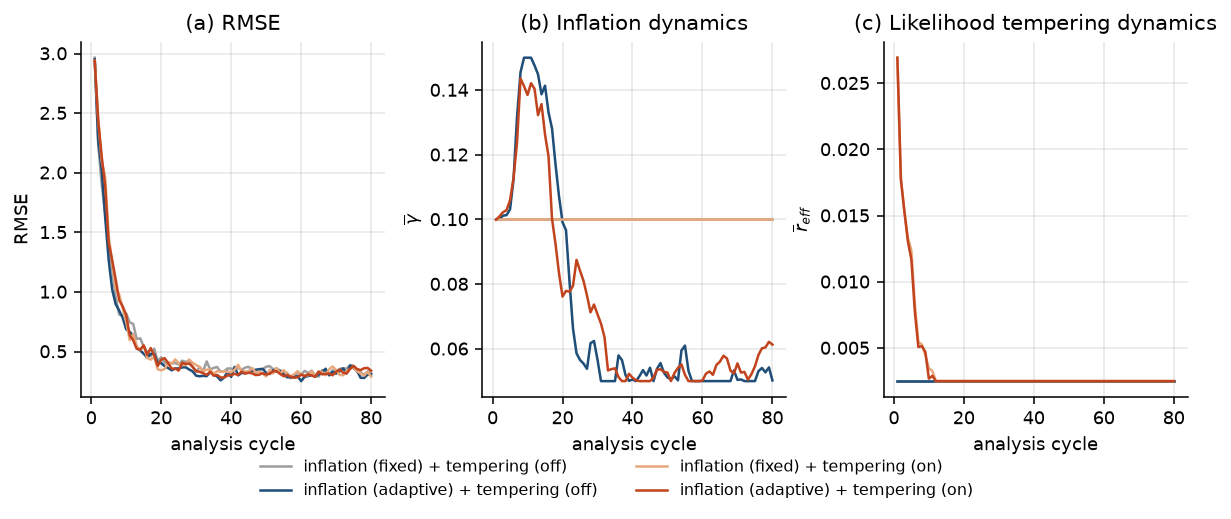

In [11]:
plt.rcParams.update({"font.size":9,"axes.grid":True,"grid.alpha":.3,"legend.frameon":False,
                     "axes.spines.top":False,"axes.spines.right":False,"figure.dpi":140,
                     "savefig.bbox":"tight","lines.linewidth":1.3})
COL = {"(a) neither":"#9e9e9e", "(b) controller only":"#1f4e79",
       "(c) annealing only":"#e8a87c", "(d) both":"#c1441e"}

# The 2x2 is named by what each adaptation is doing, rather than by a letter the reader has
# to look up: "neither" is both switched off, "both" is both switched on.
LAB = {"(a) neither":            "inflation (fixed) + tempering (off)",
       "(b) controller only":    "inflation (adaptive) + tempering (off)",
       "(c) annealing only":     "inflation (fixed) + tempering (on)",
       "(d) both":               "inflation (adaptive) + tempering (on)"}

fig, ax = plt.subplots(1, 3, figsize=(10.2, 3.3))
n = np.arange(1, N_CYCLES+1)
for m in ORD:
    H = np.asarray(HIST[m], float)          # (seeds, cycles, 7)
    with np.errstate(invalid="ignore"):
        ax[0].plot(n, np.nanmedian(H[:,:,2], 0), color=COL[m], label=LAB[m])
        ax[1].plot(n, np.nanmedian(H[:,:,4], 0), color=COL[m])
        ax[2].plot(n, np.nanmedian(H[:,:,5], 0), color=COL[m])
ax[0].set_xlabel("analysis cycle"); ax[0].set_ylabel("RMSE")
ax[0].set_title("(a) RMSE")
ax[1].set_xlabel("analysis cycle"); ax[1].set_ylabel("$\\overline{\\gamma}$")
ax[1].set_title("(b) Inflation dynamics")
ax[2].set_xlabel("analysis cycle")
ax[2].set_ylabel("$\\overline{r}_{eff}$")
ax[2].set_title("(c) Likelihood tempering dynamics")
# one legend for all three panels: the four configurations are the same curves everywhere,
# so repeating a key in each panel would spend space on nothing
h, l = ax[0].get_legend_handles_labels()
# two columns, not four: the spelled-out labels are too wide to sit on one row
fig.legend(h, l, loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, -0.14),
           columnspacing=2.5)
fig.subplots_adjust(wspace=.32)
fig.savefig("adapt2x2_fig2.pdf"); plt.show()